# **Lab 3: Ensemble Learning for Supervised Classification**


## Setup and Imports

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, BaggingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score, auc)
from xgboost import XGBClassifier
SEED = 42
np.random.seed(SEED)                      # all models also take random_state=SEED -> deterministic top to bottom
import os; from IPython.display import Markdown
os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
def caption(t): display(Markdown(t))
def show(name):
    plt.savefig(f"figs/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Loading and Preparing the Breast Cancer Dataset

The dataset has 569 samples with 30 numeric features computed from images of cell nuclei. The target `diagnosis` is **M** (malignant) or **B** (benign). We drop the `id` column (identifier only) and an empty trailing column, and encode **M = 1 (positive class)**, **B = 0**.

In [3]:
df = pd.read_csv("/content/drive/MyDrive/cancer.csv").drop(columns=["id", "Unnamed: 32"])
target_names = ["Benign", "Malignant"]
y = (df.pop("diagnosis") == "M").astype(int).values
X = df
feature_names = list(X.columns)

# Display the first 5 rows
display(X.head())

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Split into 80% Training and 20% Testing sets (stratified so class ratio is preserved)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"Dataset loaded with {X.shape[0]} samples and {X.shape[1]} features.")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print(f"Missing values: {int(X.isna().sum().sum())}")

Dataset loaded with 569 samples and 30 features.
Training set size: 455 samples
Testing set size: 114 samples
Missing values: 0


### Target Feature Instances

Let's examine the distribution of the target feature (diagnosis) in the dataset.

In [5]:
unique_targets, counts = np.unique(y, return_counts=True)
display(pd.DataFrame({"Diagnosis": [target_names[t] for t in unique_targets], "Count": counts}))
caption("**Table 1.** Class distribution of the full dataset (569 samples; 37.3 % malignant).")
print(f"\nTarget feature values (numerical): {unique_targets}")

,Diagnosis,Count
0,Benign,357
1,Malignant,212


**Table 1.** Class distribution of the full dataset (569 samples; 37.3 % malignant).


Target feature values (numerical): [0 1]


## Random Forest Classifier on the Dataset



In [7]:
rf_model = RandomForestClassifier(n_estimators=10, max_depth=5, random_state=SEED)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)

print("Random Forest Classifier Results:")
print(f"Accuracy: {rf_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, rf_preds, target_names=target_names))

Random Forest Classifier Results:
Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### Visualizing Individual Trees within the Random Forest

Each tree is trained on a bootstrapped sample with random feature selection, so every tree has a different structure. We show the first 3 trees (top 3 levels for readability).

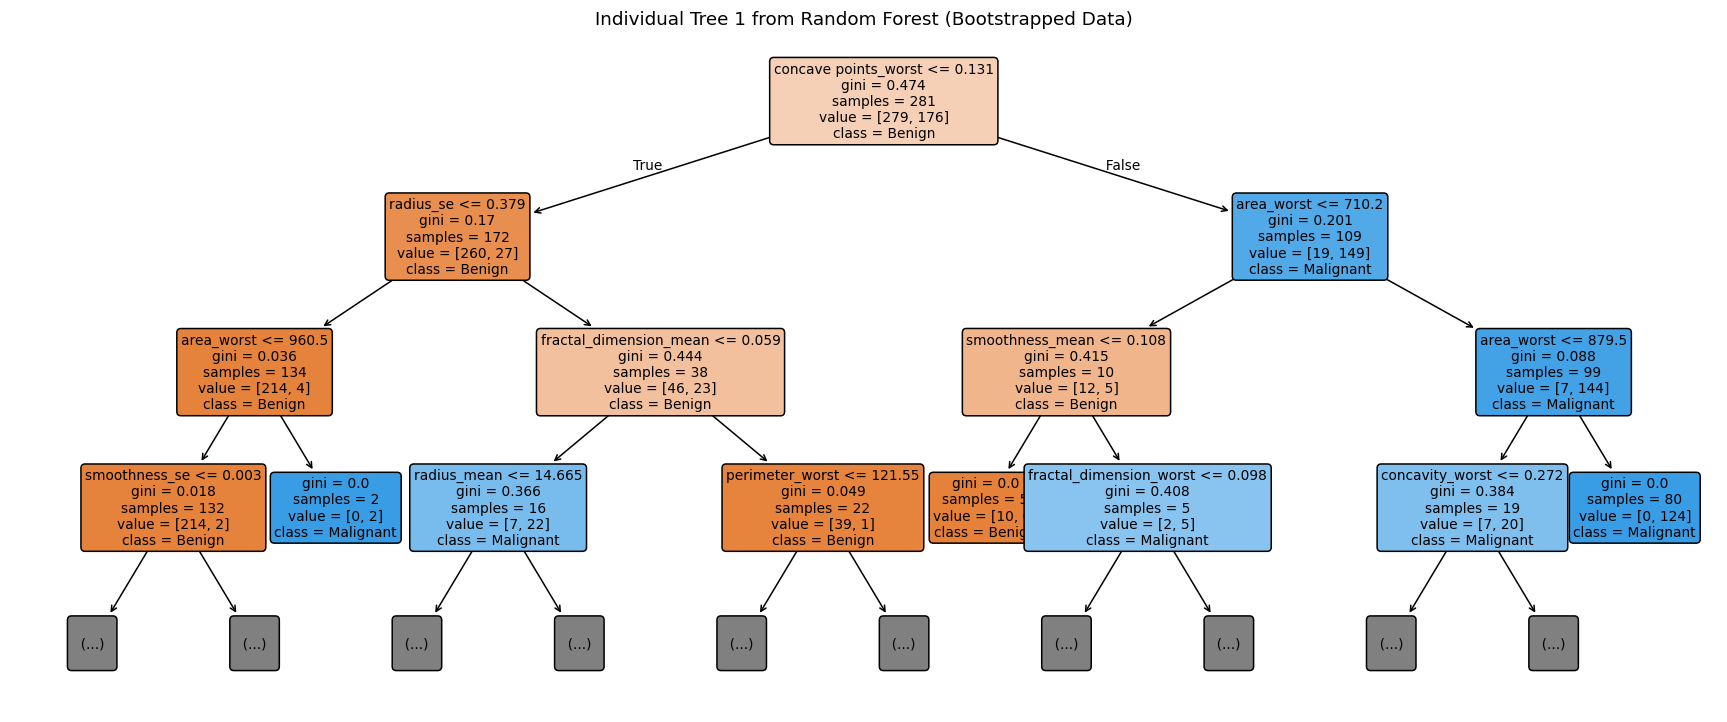

**Figure S1.** Tree 1 of the 10-tree Random Forest (top 3 levels).

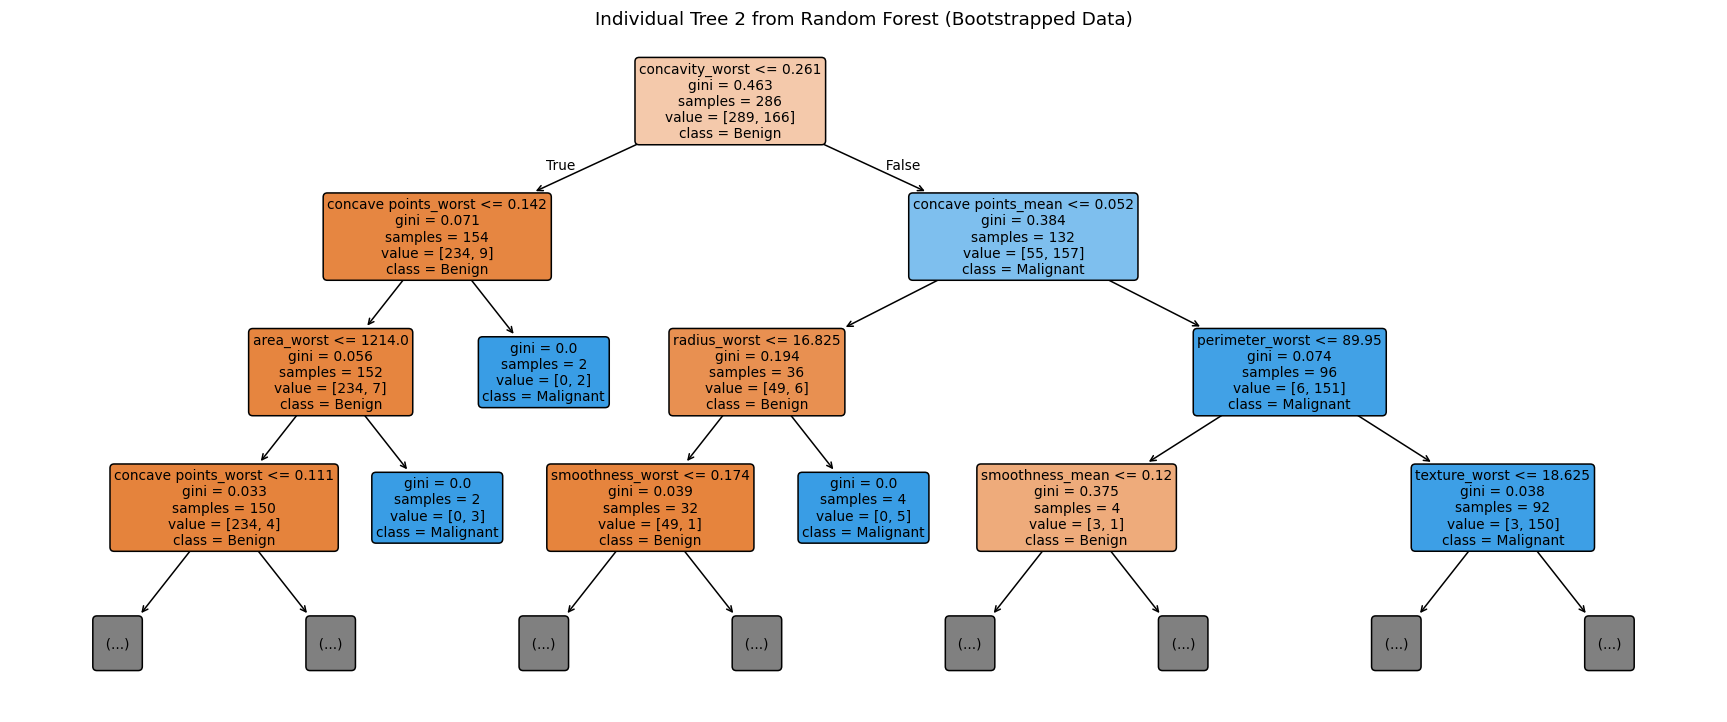

**Figure S2.** Tree 2 of the 10-tree Random Forest (top 3 levels).

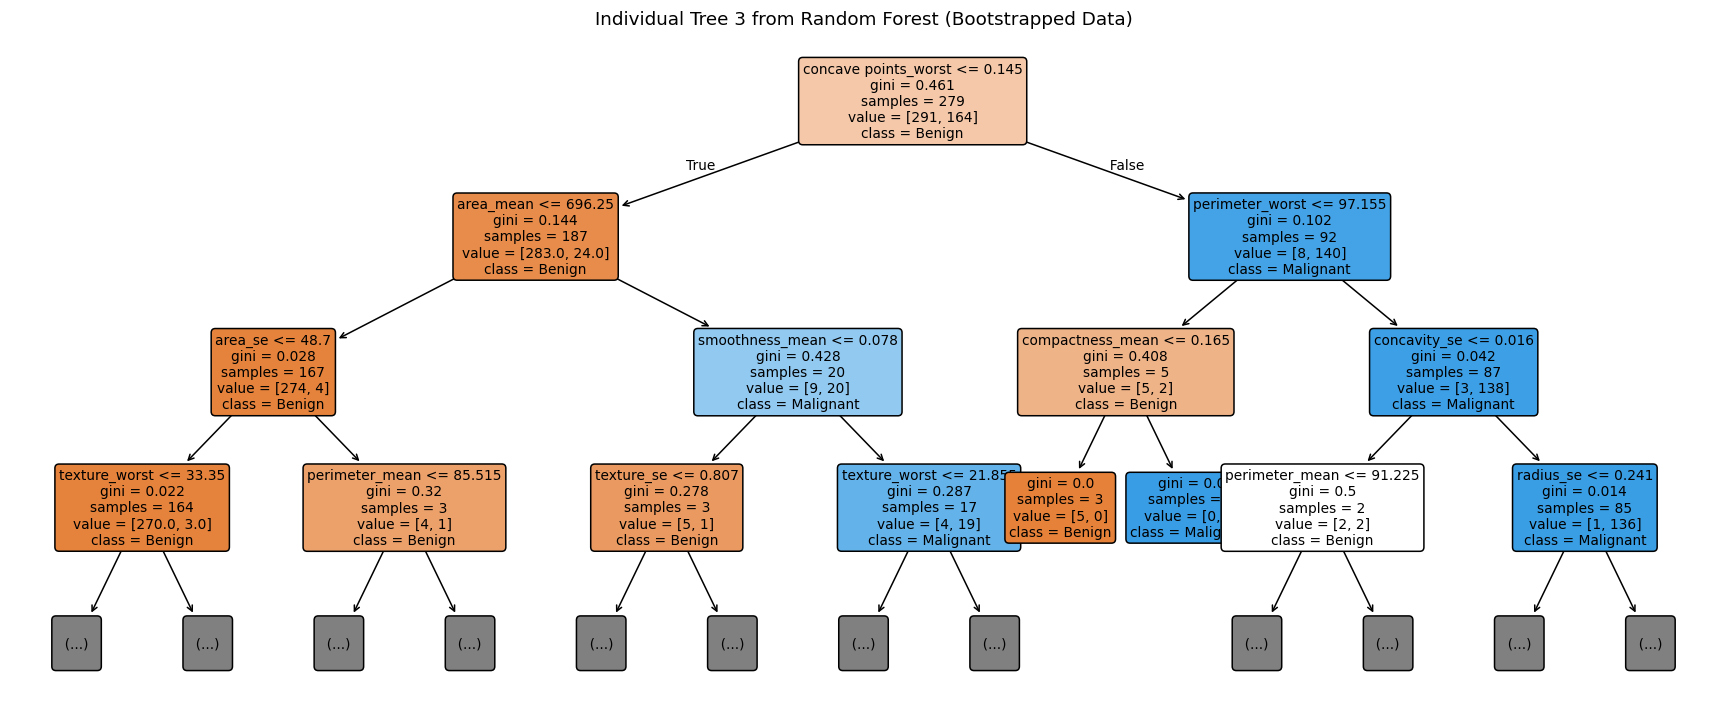

**Figure S3.** Tree 3 of the 10-tree Random Forest (top 3 levels).

In [8]:
for i, tree_in_forest in enumerate(rf_model.estimators_[:3]):
    plt.figure(figsize=(20, 8))
    plot_tree(tree_in_forest, max_depth=3, feature_names=feature_names, class_names=target_names, filled=True, rounded=True, fontsize=9)
    plt.title(f"Individual Tree {i+1} from Random Forest (Bootstrapped Data)")
    show(f"rf_tree_{i+1}")
    caption(f"**Figure S{i+1}.** Tree {i+1} of the 10-tree Random Forest (top 3 levels).")

### Demonstrating Majority Voting in Random Forest



In [9]:
print("Random Forest Final Predictions (Majority Voting Result) on first 20 test samples:\n", rf_preds[:20])
votes = np.array([t.predict(X_test.values[:5]) for t in rf_model.estimators_])   # 10 trees x 5 samples
print("\nMalignant votes (out of 10 trees) for the first 5 test samples:", votes.sum(axis=0))
display(pd.DataFrame(rf_model.predict_proba(X_test[:5]), columns=target_names, index=[f"Sample {i}" for i in range(5)]))

Random Forest Final Predictions (Majority Voting Result) on first 20 test samples:
 [0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]

Malignant votes (out of 10 trees) for the first 5 test samples: [ 0. 10.  2.  5.  0.]


,Benign,Malignant
Sample 0,0.995059,0.004941
Sample 1,0.000000,1.000000
Sample 2,0.776753,0.223247
Sample 3,0.495992,0.504008
Sample 4,0.976262,0.023738


## AdaBoost Classifier on the Dataset



In [10]:
ada_model = AdaBoostClassifier(n_estimators=60, learning_rate=1.0, random_state=SEED)
ada_model.fit(X_train, y_train)

ada_preds = ada_model.predict(X_test)
ada_acc = accuracy_score(y_test, ada_preds)

print("AdaBoost Classifier Results:")
print(f"Accuracy: {ada_acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, ada_preds, target_names=target_names))

AdaBoost Classifier Results:
Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### Visualizing a Base Estimator from AdaBoost
The weak learner is a decision stump (depth 1).

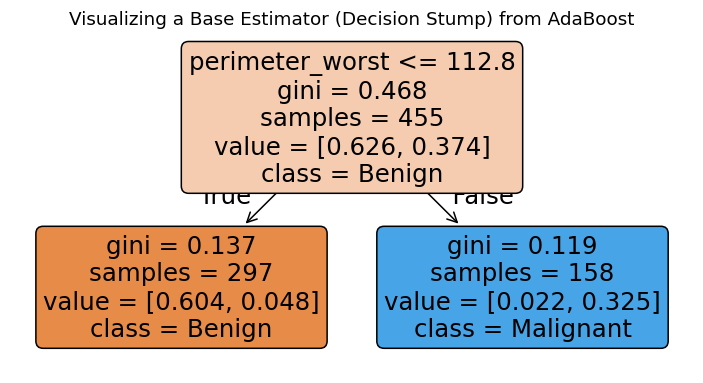

**Figure S4.** First AdaBoost weak learner (depth-1 stump).

In [11]:
plt.figure(figsize=(8, 4))
plot_tree(ada_model.estimators_[0], feature_names=feature_names, class_names=target_names, filled=True, rounded=True)
plt.title("Visualizing a Base Estimator (Decision Stump) from AdaBoost")
show("ada_stump")
caption("**Figure S4.** First AdaBoost weak learner (depth-1 stump).")

## Performance Comparison
Accuracy of both models on this dataset (80:20 split).

In [12]:
print("========================================")
print(f"Random Forest Accuracy: {rf_acc:.4f}")
print(f"AdaBoost Accuracy:      {ada_acc:.4f}")
print("========================================")

Random Forest Accuracy: 0.9649
AdaBoost Accuracy:      0.9825


# Task: Ensemble Models Evaluation


,Split,n_estimators,Random Forest,AdaBoost
0,90:10,10,0.9649,0.9649
1,90:10,50,1.0000,0.9825
2,90:10,100,1.0000,1.0000
3,90:10,150,1.0000,1.0000
4,80:20,10,0.9649,0.9386
5,80:20,50,0.9737,0.9825
6,80:20,100,0.9737,0.9737
7,80:20,150,0.9649,0.9737
8,70:30,10,0.9474,0.9591
9,70:30,50,0.9649,0.9825


Random Forest                 AdaBoost                
Split                70:30   80:20   90:10    70:30   80:20   90:10
n_estimators                                                       
10                  0.9474  0.9649  0.9649   0.9591  0.9386  0.9649
50                  0.9649  0.9737  1.0000   0.9825  0.9825  0.9825
100                 0.9649  0.9737  1.0000   0.9766  0.9737  1.0000
150                 0.9708  0.9649  1.0000   0.9766  0.9737  1.0000

**Table 2.** Test accuracy of Random Forest and AdaBoost for each train:test split and n_estimators (stratified split, seed 42; one split per cell, so differences of one sample are within noise).

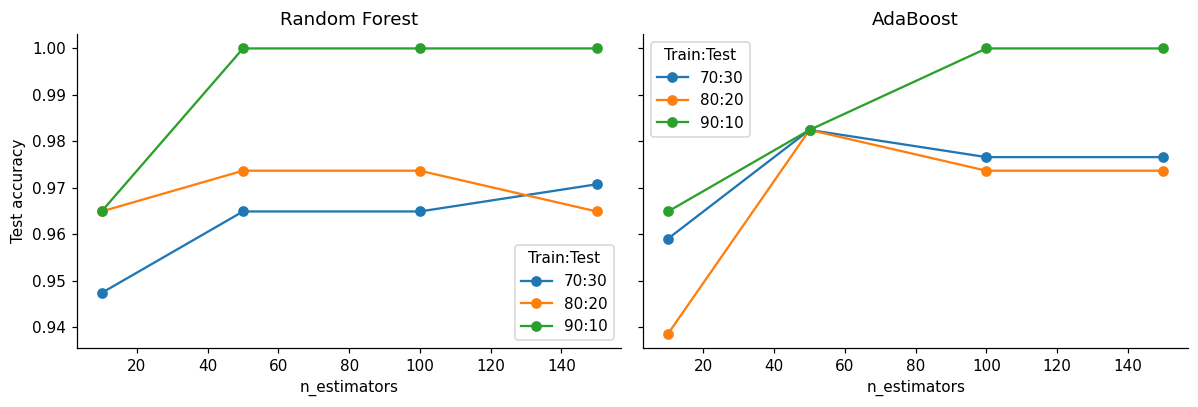

**Figure 1.** Test accuracy versus n_estimators for the three train:test splits.

In [13]:
rows = []
for test_size, label in [(0.10, "90:10"), (0.20, "80:20"), (0.30, "70:30")]:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=test_size, stratify=y, random_state=SEED)
    for n in [10, 50, 100, 150]:
        rf_ = RandomForestClassifier(n_estimators=n, random_state=SEED).fit(Xa, ya)
        ad_ = AdaBoostClassifier(n_estimators=n, random_state=SEED).fit(Xa, ya)
        rows.append({"Split": label, "n_estimators": n,
                     "Random Forest": accuracy_score(yb, rf_.predict(Xb)),
                     "AdaBoost": accuracy_score(yb, ad_.predict(Xb))})
acc_table = pd.DataFrame(rows)
display(acc_table.round(4))
display(acc_table.pivot(index="n_estimators", columns="Split", values=["Random Forest", "AdaBoost"]).round(4))
caption("**Table 2.** Test accuracy of Random Forest and AdaBoost for each train:test split and n_estimators (stratified split, seed 42; one split per cell, so differences of one sample are within noise).")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, m in zip(ax, ["Random Forest", "AdaBoost"]):
    for s, g in acc_table.groupby("Split"):
        a.plot(g["n_estimators"], g[m], marker="o", label=s)
    a.set(title=m, xlabel="n_estimators"); a.legend(title="Train:Test")
ax[0].set_ylabel("Test accuracy"); plt.tight_layout(); show("acc_vs_n")
caption("**Figure 1.** Test accuracy versus n_estimators for the three train:test splits.")

## Task 1: Baseline Decision Tree

In [14]:
dt = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
print(f"Baseline Decision Tree – train accuracy: {dt.score(X_train, y_train):.4f}, test accuracy: {dt.score(X_test, y_test):.4f}")
caption("The unpruned tree fits the training data perfectly (train 1.000) but generalises worse – a high-variance baseline.")

Baseline Decision Tree – train accuracy: 1.0000, test accuracy: 0.9298


The unpruned tree fits the training data perfectly (train 1.000) but generalises worse – a high-variance baseline.

## Tasks 2–4: Define the models



In [15]:
inner = StratifiedKFold(3, shuffle=True, random_state=SEED)
grid_ada = {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 0.5, 1.0]}
grid_xgb = {"n_estimators": [50, 100, 200], "learning_rate": [0.03, 0.1, 0.3]}

def make_lr():  return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED))
def make_rf():  return RandomForestClassifier(n_estimators=300, random_state=SEED)
def make_xgb(**kw): return XGBClassifier(max_depth=3, eval_metric="logloss", random_state=SEED, n_jobs=1, **kw)

models = {
    "Decision Tree (baseline)": DecisionTreeClassifier(random_state=SEED),
    "Bagging": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=SEED),
    "Random Forest": make_rf(),
    "AdaBoost (tuned)": GridSearchCV(AdaBoostClassifier(random_state=SEED), grid_ada, cv=inner, scoring="f1_macro"),
    "XGBoost (tuned)": GridSearchCV(make_xgb(), grid_xgb, cv=inner, scoring="f1_macro"),
    "Soft Voting (LR+RF+XGB)": VotingClassifier([("lr", make_lr()), ("rf", make_rf()), ("xgb", make_xgb(n_estimators=100, learning_rate=0.1))], voting="soft"),
    "Stacking (LR+RF+XGB)": StackingClassifier([("lr", make_lr()), ("rf", make_rf()), ("xgb", make_xgb(n_estimators=100, learning_rate=0.1))],
                                               final_estimator=LogisticRegression(max_iter=5000), cv=5),
}

# Best hyper-parameters found on the full training set
for name in ["AdaBoost (tuned)", "XGBoost (tuned)"]:
    g = models[name].fit(X_train, y_train)
    print(f"{name}: best params = {g.best_params_}, inner-CV macro-F1 = {g.best_score_:.4f}")
caption("**Table 3.** Best hyper-parameters from the grid search on the training set (AdaBoost: n_estimators ∈ {50,100,200} × learning_rate ∈ {0.1,0.5,1.0}; XGBoost: n_estimators ∈ {50,100,200} × learning_rate ∈ {0.03,0.1,0.3}, max_depth 3).")

AdaBoost (tuned): best params = {'learning_rate': 1.0, 'n_estimators': 200}, inner-CV macro-F1 = 0.9695
XGBoost (tuned): best params = {'learning_rate': 0.03, 'n_estimators': 200}, inner-CV macro-F1 = 0.9574


**Table 3.** Best hyper-parameters from the grid search on the training set (AdaBoost: n_estimators ∈ {50,100,200} × learning_rate ∈ {0.1,0.5,1.0}; XGBoost: n_estimators ∈ {50,100,200} × learning_rate ∈ {0.03,0.1,0.3}, max_depth 3).

## Task 5: 5-fold Stratified Cross-Validation


In [16]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=2)
    rows.append({"Model": name,
                 "Accuracy": f"{r['test_accuracy'].mean():.4f} ± {r['test_accuracy'].std():.4f}",
                 "Macro-F1": f"{r['test_f1_macro'].mean():.4f} ± {r['test_f1_macro'].std():.4f}",
                 "Fit time / fold (s)": f"{r['fit_time'].mean():.2f} ± {r['fit_time'].std():.2f}",
                 "_f1": r["test_f1_macro"].mean(), "_acc": r["test_accuracy"].mean()})
cv_res = pd.DataFrame(rows)
display(cv_res.drop(columns=["_f1", "_acc"]).set_index("Model"))
caption("**Table 4.** 5-fold stratified CV on the training set (455 rows): mean ± SD of accuracy and macro-F1, and fit time per fold. Tuned models use nested CV and their time includes the grid search.")
best_name = cv_res.sort_values(["_f1", "_acc"], ascending=False).iloc[0]["Model"]
print("Best model by mean CV macro-F1 (accuracy as tie-break):", best_name)

,Accuracy,Macro-F1,Fit time / fold (s)
Model,,,
Decision Tree (baseline),0.9231 ± 0.0326,0.9175 ± 0.0352,0.03 ± 0.01
Bagging,0.9626 ± 0.0226,0.9599 ± 0.0241,1.83 ± 0.34
Random Forest,0.9604 ± 0.0164,0.9574 ± 0.0178,1.29 ± 0.20
AdaBoost (tuned),0.9758 ± 0.0082,0.9740 ± 0.0089,12.19 ± 1.72
XGBoost (tuned),0.9670 ± 0.0120,0.9646 ± 0.0129,3.01 ± 0.79
Soft Voting (LR+RF+XGB),0.9780 ± 0.0098,0.9765 ± 0.0105,0.78 ± 0.11
Stacking (LR+RF+XGB),0.9780 ± 0.0070,0.9765 ± 0.0075,5.10 ± 0.89


**Table 4.** 5-fold stratified CV on the training set (455 rows): mean ± SD of accuracy and macro-F1, and fit time per fold. Tuned models use nested CV and their time includes the grid search.

Best model by mean CV macro-F1 (accuracy as tie-break): Soft Voting (LR+RF+XGB)


## Task 8 (step 1): Choose the decision threshold from out-of-fold predictions — *before* the test set is used for the best model


OOF cost at 0.5: 64 | OOF cost at frozen threshold 0.198: 48 (1 tied candidate(s))


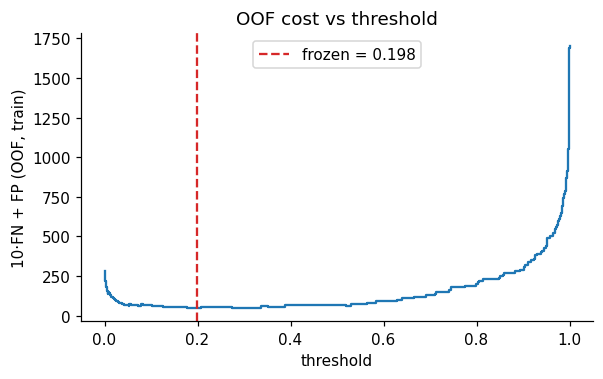

**Figure 2.** Out-of-fold cost 10·FN + FP on the training set as a function of the threshold; the dashed line is the frozen value.

In [17]:
from sklearn.base import clone
best_cv = clone(models[best_name])
oof = cross_val_predict(best_cv, X_train, y_train, cv=cv, method="predict_proba", n_jobs=2)[:, 1]
def cost(t, yt, p):
    pred = p >= t
    return 10 * ((~pred) & (yt == 1)).sum() + (pred & (yt == 0)).sum()
cand = np.unique(np.concatenate([oof, [0.0, 1.0]]))
costs = np.array([cost(t, y_train, oof) for t in cand])
ties = cand[costs == costs.min()]
THRESH = float(np.median(ties))            # middle of the cheapest candidates; FROZEN from here on
print(f"OOF cost at 0.5: {cost(0.5, y_train, oof)} | OOF cost at frozen threshold {THRESH:.3f}: {costs.min()} ({len(ties)} tied candidate(s))")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(cand, costs, drawstyle="steps-post"); ax.axvline(THRESH, color="C3", ls="--", label=f"frozen = {THRESH:.3f}")
ax.set(xlabel="threshold", ylabel="10·FN + FP (OOF, train)", title="OOF cost vs threshold"); ax.legend()
show("cost_vs_threshold")
caption("**Figure 2.** Out-of-fold cost 10·FN + FP on the training set as a function of the threshold; the dashed line is the frozen value.")

## Task 6: Confusion matrix of the best model – metrics by hand vs scikit-learn
The best model is refit on the training set and evaluated on the test set at the **frozen** threshold.

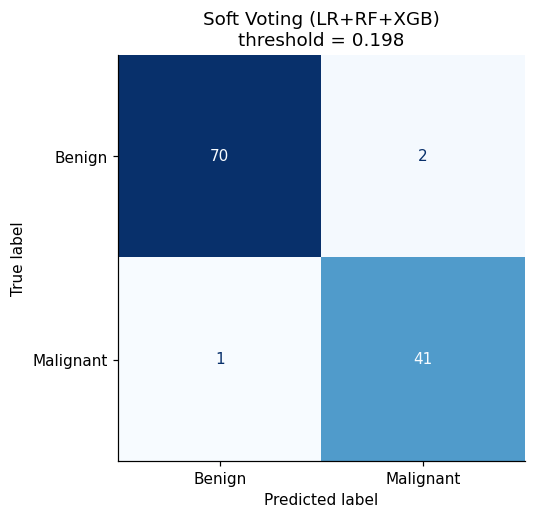

**Figure 3.** Test-set confusion matrix of the best model at the frozen threshold (TN=70, FP=2, FN=1, TP=41).

,By hand,scikit-learn,Match
Precision,0.9535,0.9535,True
Recall,0.9762,0.9762,True
Specificity,0.9722,0.9722,True
F1,0.9647,0.9647,True


**Table 5.** Precision = TP/(TP+FP), recall = TP/(TP+FN), specificity = TN/(TN+FP), F1 = 2PR/(P+R), computed by hand from Figure 3 and verified against scikit-learn.

In [18]:
best_model = models[best_name].fit(X_train, y_train)
p_test = best_model.predict_proba(X_test)[:, 1]
y_pred = (p_test >= THRESH).astype(int)
y_pred05 = (p_test >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(cmap="Blues", colorbar=False)
plt.title(f"{best_name}\nthreshold = {THRESH:.3f}"); show("confusion_matrix")
caption(f"**Figure 3.** Test-set confusion matrix of the best model at the frozen threshold (TN={TN}, FP={FP}, FN={FN}, TP={TP}).")

# By hand from the matrix entries
precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
specificity = TN / (TN + FP)
f1          = 2 * precision * recall / (precision + recall)
sk = {"Precision": precision_score(y_test, y_pred), "Recall": recall_score(y_test, y_pred),
      "Specificity": recall_score(y_test, y_pred, pos_label=0), "F1": f1_score(y_test, y_pred)}
check = pd.DataFrame({"By hand": {"Precision": precision, "Recall": recall, "Specificity": specificity, "F1": f1}, "scikit-learn": sk})
check["Match"] = np.isclose(check["By hand"], check["scikit-learn"])
display(check.round(4)); assert check["Match"].all()
caption("**Table 5.** Precision = TP/(TP+FP), recall = TP/(TP+FN), specificity = TN/(TN+FP), F1 = 2PR/(P+R), computed by hand from Figure 3 and verified against scikit-learn.")

## Task 7: ROC and Precision–Recall curves (best model, test set)

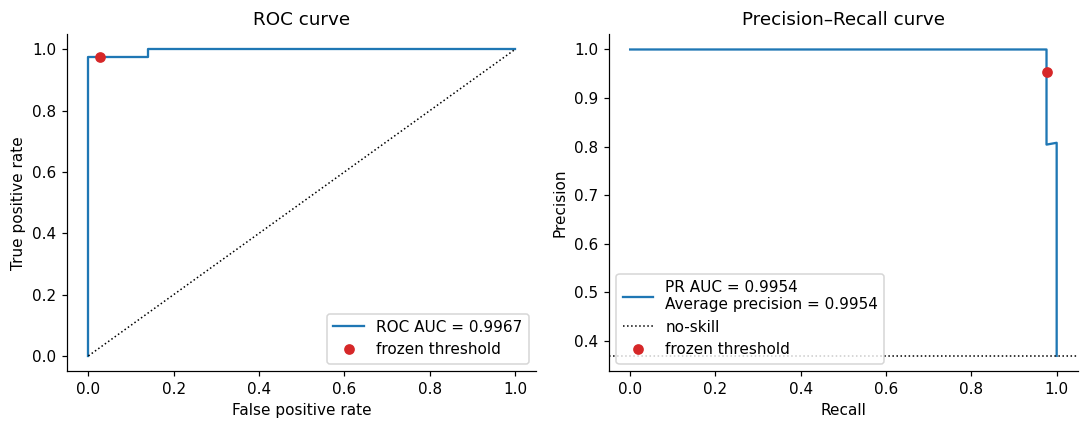

**Figure 4.** ROC (left) and precision–recall (right) curves of the best model on the test set; the red dot marks the frozen threshold.

ROC AUC = 0.9967 | PR AUC (trapezoid) = 0.9954 | Average precision = 0.9954


In [19]:
fpr, tpr, _ = roc_curve(y_test, p_test)
prec, rec, _ = precision_recall_curve(y_test, p_test)
roc_auc = roc_auc_score(y_test, p_test); pr_auc = auc(rec, prec); ap = average_precision_score(y_test, p_test)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.4f}"); ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].plot(FP / (FP + TN), TP / (TP + FN), "o", color="C3", label="frozen threshold")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve"); ax[0].legend(loc="lower right")
ax[1].plot(rec, prec, label=f"PR AUC = {pr_auc:.4f}\nAverage precision = {ap:.4f}")
ax[1].axhline(y_test.mean(), color="k", ls=":", lw=1, label="no-skill")
ax[1].plot(recall, precision, "o", color="C3", label="frozen threshold")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curve"); ax[1].legend(loc="lower left")
plt.tight_layout(); show("roc_pr")
caption("**Figure 4.** ROC (left) and precision–recall (right) curves of the best model on the test set; the red dot marks the frozen threshold.")
print(f"ROC AUC = {roc_auc:.4f} | PR AUC (trapezoid) = {pr_auc:.4f} | Average precision = {ap:.4f}")

## Task 8 (step 2): Test-set cost with the frozen threshold

In [20]:
def summary(pred):
    t = confusion_matrix(y_test, pred).ravel()
    return {"TN": t[0], "FP": t[1], "FN": t[2], "TP": t[3], "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "Specificity": recall_score(y_test, pred, pos_label=0),
            "F1": f1_score(y_test, pred), "Cost 10·FN+FP": 10 * t[2] + t[1]}
thr_table = pd.DataFrame({"threshold 0.5": summary(y_pred05), f"frozen {THRESH:.3f}": summary(y_pred)}).T
display(thr_table.round(4))
caption("**Table 6.** Test-set results at the default 0.5 threshold and at the frozen, OOF-selected threshold. The threshold was never tuned on the test set.")

,TN,FP,FN,TP,Precision,Recall,Specificity,F1,Cost 10·FN+FP
threshold 0.5,72.0,0.0,3.0,39.0,1.0000,0.9286,1.0000,0.9630,30.0
frozen 0.198,70.0,2.0,1.0,41.0,0.9535,0.9762,0.9722,0.9647,12.0


**Table 6.** Test-set results at the default 0.5 threshold and at the frozen, OOF-selected threshold. The threshold was never tuned on the test set.

## Task 9: Random Forest feature importances

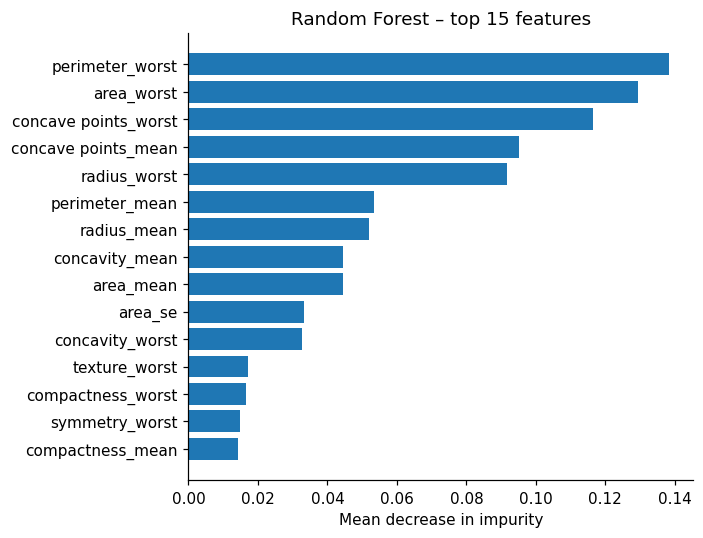

**Figure 5.** Random Forest (500 trees, training set) impurity-based feature importances, top 15.

,importance
perimeter_worst,0.1383
area_worst,0.1295
concave points_worst,0.1164
concave points_mean,0.0951
radius_worst,0.0917


**Table 7.** Top five features (together 57.1% of total importance).

,perimeter_worst,area_worst,concave points_worst,concave points_mean,radius_worst
perimeter_worst,1.00,0.98,0.82,0.86,0.99
area_worst,0.98,1.00,0.75,0.82,0.98
concave points_worst,0.82,0.75,1.00,0.91,0.79
concave points_mean,0.86,0.82,0.91,1.00,0.84
radius_worst,0.99,0.98,0.79,0.84,1.00


**Table 8.** Pairwise correlation of the top five features (training set).

In [21]:
rf_full = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=2).fit(X_train, y_train)
imp = pd.Series(rf_full.feature_importances_, index=feature_names).sort_values(ascending=False)
top = imp.head(15)[::-1]
plt.figure(figsize=(6.5, 5)); plt.barh(top.index, top.values); plt.xlabel("Mean decrease in impurity")
plt.title("Random Forest – top 15 features"); plt.tight_layout(); show("feature_importance")
caption("**Figure 5.** Random Forest (500 trees, training set) impurity-based feature importances, top 15.")
top5 = imp.head(5); cols = list(top5.index)
display(pd.DataFrame({"importance": top5}).round(4))
caption(f"**Table 7.** Top five features (together {top5.sum():.1%} of total importance).")
display(X_train[cols].corr().round(2))
caption("**Table 8.** Pairwise correlation of the top five features (training set).")